In [1]:
# Cell 1 — Install dependencies
!pip install -q monai scipy scikit-learn matplotlib seaborn tqdm opencv-python-headless


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 58.6 MB/s eta 0:00:00


In [2]:
# Cell 2 — Imports & Config
# FIX: use torch.amp (not deprecated torch.cuda.amp)
# FIX: import cv2 at module level, not inside __getitem__
import os, re, random, json, time, math
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from pathlib import Path
from collections import defaultdict
from tqdm.notebook import tqdm, trange
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.ndimage import distance_transform_edt
from torch.amp import autocast, GradScaler   # FIX: torch.amp, not torch.cuda.amp

# Transformers import for VLM text encoder
from transformers import AutoTokenizer, AutoModel
import torchvision.models as models
from torchvision.models import ResNet34_Weights

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMG_DIR      = "/kaggle/input/datasets/hussainnasirkhan/flair-brats2020/FLAIR_BRATS2020_split/train/images"
MASK_DIR     = "/kaggle/input/datasets/hussainnasirkhan/flair-brats2020/FLAIR_BRATS2020_split/train/masks"
VAL_IMG_DIR  = "/kaggle/input/datasets/hussainnasirkhan/flair-brats2020/FLAIR_BRATS2020_split/val/images"
VAL_MASK_DIR = "/kaggle/input/datasets/hussainnasirkhan/flair-brats2020/FLAIR_BRATS2020_split/val/masks"

# Path to TextBraTS free-text radiology reports
TEXT_DIR     = "/kaggle/input/datasets/ponnurukarthik/textbrats/TextBraTSData"
TEXT_MODEL_NAME = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
USE_TEXT     = True
ALIGN_COEFF  = 0.10

IMG_SIZE   = 128
BATCH_SIZE = 16
NUM_EPOCHS = 100
LR         = 1e-4
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device       : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")
print(f"Batch size   : {BATCH_SIZE}")
print(f"Total epochs : {NUM_EPOCHS}")
print(f"Text Encoder : {TEXT_MODEL_NAME}")


Device       : cuda
PyTorch      : 2.10.0+cu128
Batch size   : 16
Total epochs : 100
Text Encoder : microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext


In [3]:
# Cell 3 — Volume inventory
def get_vol_idx(fname):
    m = re.search(r'_(\d+)\.npy$', str(fname))
    return int(m.group(1)) if m else None

def inventory_volumes(img_dir, mask_dir):
    img_files  = sorted(Path(img_dir).glob("image_*.npy"),
                        key=lambda f: get_vol_idx(f))
    mask_files = sorted(Path(mask_dir).glob("mask_*.npy"),
                        key=lambda f: get_vol_idx(f))
    img_idx  = {get_vol_idx(f): f for f in img_files}
    mask_idx = {get_vol_idx(f): f for f in mask_files}
    common   = sorted(img_idx.keys() & mask_idx.keys())
    entries  = [(img_idx[i], mask_idx[i], i) for i in common]
    print(f"  {Path(img_dir).parent.name}: {len(entries)} volumes")
    return entries

print("=== Inventory ===")
train_vols = inventory_volumes(IMG_DIR, MASK_DIR)
val_vols   = inventory_volumes(VAL_IMG_DIR, VAL_MASK_DIR)

=== Inventory ===
  train: 258 volumes
  val: 86 volumes


In [4]:
# Cell 4 — Load ALL 2D slices into RAM  (2.5D-ready)
# Each record now stores:
#   img_prev, img_curr, img_next  -> 3-channel input (2.5D context)
#   wt, tc, et                    -> segmentation targets
#   pid, et_size, tc_size
#   report                        -> free-text radiology report content

def load_slices_into_ram(vol_entries, split="train"):
    records = []
    print(f"Loading {split} slices into RAM ...")
    
    # Text directory mapping
    text_base_dir = Path("c:/flair/TextBraTSData/TextBraTSData")
    
    for img_path, msk_path, vol_idx in tqdm(vol_entries, desc=f"  {split}"):
        img_vol = np.load(str(img_path)).astype(np.float32)
        msk_vol = np.load(str(msk_path)).astype(np.float32)

        # Load radiology report text
        report_folder = text_base_dir / f"BraTS20_Training_{vol_idx:03d}"
        report_file = report_folder / f"BraTS20_Training_{vol_idx:03d}_flair_text.txt"
        if report_file.exists():
            with open(report_file, "r", encoding="utf-8") as f:
                report_text = f.read().strip()
        else:
            report_text = "Brain MRI FLAIR sequence showing tumor."

        # Robust per-volume normalisation
        p1  = np.percentile(img_vol, 1)
        p99 = np.percentile(img_vol, 99)
        img_vol = np.clip(img_vol, p1, p99)
        img_vol = (img_vol - p1) / (p99 - p1 + 1e-6)

        n_slices = img_vol.shape[2]
        for sl in range(n_slices):
            msk_sl = msk_vol[:, :, sl, :]
            wt = ((msk_sl[...,1]+msk_sl[...,2]+msk_sl[...,3]) > 0).astype(np.float32)
            if wt.sum() < 5:
                continue
            tc = ((msk_sl[...,1]+msk_sl[...,3]) > 0).astype(np.float32)
            et = (msk_sl[...,3] > 0).astype(np.float32)

            # 2.5D: clamp neighbour indices
            sl_prev = max(0, sl - 1)
            sl_next = min(n_slices - 1, sl + 1)

            records.append({
                "img_prev": img_vol[:, :, sl_prev].copy(),
                "img_curr": img_vol[:, :, sl].copy(),
                "img_next": img_vol[:, :, sl_next].copy(),
                "wt":       wt,
                "tc":       tc,
                "et":       et,
                "pid":      vol_idx,
                "et_size":  int(et.sum()),
                "tc_size":  int(tc.sum()),
                "report":   report_text,
            })

    print(f"  Kept {len(records)} tumor-positive slices")
    tc_zero = sum(r["tc_size"]==0 for r in records)
    et_zero = sum(r["et_size"]==0 for r in records)
    print(f"  Slices with TC=0: {tc_zero} ({tc_zero/len(records)*100:.1f}%)")
    print(f"  Slices with ET=0: {et_zero} ({et_zero/len(records)*100:.1f}%)")
    return records

train_cache   = load_slices_into_ram(train_vols, "train")
val_cache_raw = load_slices_into_ram(val_vols,   "val")
print(f"\nTrain slices : {len(train_cache)}")
print(f"Val slices   : {len(val_cache_raw)}")


Loading train slices into RAM ...


  train:   0%|          | 0/258 [00:00<?, ?it/s]

  Kept 17084 tumor-positive slices
  Slices with TC=0: 5161 (30.2%)
  Slices with ET=0: 6940 (40.6%)
Loading val slices into RAM ...


  val:   0%|          | 0/86 [00:00<?, ?it/s]

  Kept 5864 tumor-positive slices
  Slices with TC=0: 1743 (29.7%)
  Slices with ET=0: 2277 (38.8%)

Train slices : 17084
Val slices   : 5864


In [5]:
# Cell 5 — Datasets + 2.5D + difficulty sampler
# FIX: cv2 imported at top of Cell 2 (not inside __getitem__)
# FIX: elastic deform — prev/nxt use independent random deformation fields

import scipy.ndimage as _ndi

def elastic_deform_2d(img, wt, tc, et, alpha=12, sigma=4):
    """Deform image + masks together with one shared random field."""
    H, W = img.shape
    dx = _ndi.gaussian_filter(np.random.randn(H, W).astype(np.float32) * alpha, sigma)
    dy = _ndi.gaussian_filter(np.random.randn(H, W).astype(np.float32) * alpha, sigma)
    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
    coords = [np.clip(yy + dy, 0, H - 1), np.clip(xx + dx, 0, W - 1)]
    img_d = _ndi.map_coordinates(img, coords, order=1, mode='reflect').astype(np.float32)
    wt_d  = (_ndi.map_coordinates(wt,  coords, order=0, mode='reflect') > 0.5).astype(np.float32)
    tc_d  = (_ndi.map_coordinates(tc,  coords, order=0, mode='reflect') > 0.5).astype(np.float32)
    et_d  = (_ndi.map_coordinates(et,  coords, order=0, mode='reflect') > 0.5).astype(np.float32)
    return img_d, wt_d, tc_d, et_d

def elastic_deform_img_only(img, alpha=12, sigma=4):
    """Deform an image with an INDEPENDENT random field (safe for prev/nxt context channels)."""
    H, W = img.shape
    dx = _ndi.gaussian_filter(np.random.randn(H, W).astype(np.float32) * alpha, sigma)
    dy = _ndi.gaussian_filter(np.random.randn(H, W).astype(np.float32) * alpha, sigma)
    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
    coords = [np.clip(yy + dy, 0, H - 1), np.clip(xx + dx, 0, W - 1)]
    return _ndi.map_coordinates(img, coords, order=1, mode='reflect').astype(np.float32)


class BraTS2DTrainDataset(Dataset):
    def __init__(self, records, tokenizer=None):
        self.records = records
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec  = self.records[idx]
        prev = rec["img_prev"].copy()
        curr = rec["img_curr"].copy()
        nxt  = rec["img_next"].copy()
        wt   = rec["wt"].copy()
        tc   = rec["tc"].copy()
        et   = rec["et"].copy()
        report = rec["report"]

        # Consistent geometric aug on all channels + masks
        do_hflip = random.random() > 0.5
        do_vflip = random.random() > 0.5
        rot_k    = random.randint(1, 3) if random.random() > 0.5 else 0

        def geom(arr):
            if do_hflip: arr = np.fliplr(arr).copy()
            if do_vflip: arr = np.flipud(arr).copy()
            if rot_k:    arr = np.rot90(arr, rot_k).copy()
            return arr

        prev = geom(prev); curr = geom(curr); nxt = geom(nxt)
        wt   = geom(wt);   tc   = geom(tc);   et  = geom(et)

        # FIX: curr+masks share one elastic field; prev/nxt get independent fields
        if random.random() > 0.70:
            curr, wt, tc, et = elastic_deform_2d(curr, wt, tc, et)
            prev = elastic_deform_img_only(prev)
            nxt  = elastic_deform_img_only(nxt)

        # Random crop — same spatial crop for all 3 channels
        if random.random() > 0.5:
            H, W = curr.shape
            half = random.randint(int(H * 0.35), int(H * 0.50))
            cy   = random.randint(half, H - half)
            cx   = random.randint(half, W - half)
            y0, y1 = cy - half, cy + half
            x0, x1 = cx - half, cx + half
            prev = cv2.resize(prev[y0:y1, x0:x1], (W, H), interpolation=cv2.INTER_LINEAR)
            curr = cv2.resize(curr[y0:y1, x0:x1], (W, H), interpolation=cv2.INTER_LINEAR)
            nxt  = cv2.resize(nxt[y0:y1,  x0:x1], (W, H), interpolation=cv2.INTER_LINEAR)
            wt   = cv2.resize(wt[y0:y1,   x0:x1], (W, H), interpolation=cv2.INTER_NEAREST)
            tc   = cv2.resize(tc[y0:y1,   x0:x1], (W, H), interpolation=cv2.INTER_NEAREST)
            et   = cv2.resize(et[y0:y1,   x0:x1], (W, H), interpolation=cv2.INTER_NEAREST)

        # Intensity aug — coherent scale/shift across all 3 channels
        scale = np.random.uniform(0.85, 1.15)
        shift = np.random.uniform(-0.10, 0.10)
        prev  = np.clip(prev * scale + shift, 0, 1).astype(np.float32)
        curr  = np.clip(curr * scale + shift, 0, 1).astype(np.float32)
        nxt   = np.clip(nxt  * scale + shift, 0, 1).astype(np.float32)
        if random.random() > 0.5:
            curr = np.clip(curr + np.random.normal(0, 0.02, curr.shape).astype(np.float32), 0, 1)
        if random.random() > 0.5:
            curr = np.power(curr, np.random.uniform(0.80, 1.25)).astype(np.float32)

        img_25d = np.stack([prev, curr, nxt], axis=0)
        masks   = np.stack([wt, tc, et], axis=0)
        
        # Tokenize text report
        if self.tokenizer is not None:
            tokens = self.tokenizer(
                report,
                padding="max_length",
                max_length=128,
                truncation=True,
                return_tensors="pt"
            )
            input_ids = tokens["input_ids"].squeeze(0)
            attention_mask = tokens["attention_mask"].squeeze(0)
        else:
            input_ids = torch.zeros(128, dtype=torch.long)
            attention_mask = torch.zeros(128, dtype=torch.long)

        return (torch.from_numpy(img_25d).float(),
                torch.from_numpy(masks).float(),
                rec["pid"],
                input_ids,
                attention_mask)


class BraTS2DValDataset(Dataset):
    def __init__(self, records, tokenizer=None):
        self.records = records
        self.tokenizer = tokenizer
        
    def __len__(self):
        return len(self.records)
        
    def __getitem__(self, idx):
        rec     = self.records[idx]
        img_25d = np.stack([rec["img_prev"], rec["img_curr"], rec["img_next"]], axis=0)
        masks   = np.stack([rec["wt"], rec["tc"], rec["et"]], axis=0)
        report  = rec["report"]
        
        # Tokenize text report
        if self.tokenizer is not None:
            tokens = self.tokenizer(
                report,
                padding="max_length",
                max_length=128,
                truncation=True,
                return_tensors="pt"
            )
            input_ids = tokens["input_ids"].squeeze(0)
            attention_mask = tokens["attention_mask"].squeeze(0)
        else:
            input_ids = torch.zeros(128, dtype=torch.long)
            attention_mask = torch.zeros(128, dtype=torch.long)
            
        return (torch.from_numpy(img_25d).float(),
                torch.from_numpy(masks).float(),
                rec["pid"],
                input_ids,
                attention_mask)


def get_difficulty_weights(records):
    weights = np.zeros(len(records), dtype=np.float32)
    for i, r in enumerate(records):
        et_size = r["et_size"]; tc_size = r["tc_size"]
        if et_size > 0:
            w = 5.0 / np.sqrt(max(et_size, 1))
        elif tc_size > 0:
            w = 2.0 / np.sqrt(max(tc_size, 1))
        else:
            w = 0.10
        weights[i] = w
    return weights / weights.sum()


tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME)
train_ds = BraTS2DTrainDataset(train_cache, tokenizer)
val_ds   = BraTS2DValDataset(val_cache_raw, tokenizer)

diff_weights = get_difficulty_weights(train_cache)
sampler = WeightedRandomSampler(weights=diff_weights,
                                num_samples=len(train_cache), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=2, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=True)

print(f"Train: {len(train_ds)} slices | Val: {len(val_ds)} slices")
batch_out = next(iter(train_loader))
imgs, masks, pids, input_ids, attention_mask = batch_out
print(f"Batch — imgs: {imgs.shape}, masks: {masks.shape}, input_ids: {input_ids.shape}")
print(f"Mean mask% — WT:{masks[:,0].mean()*100:.1f}% TC:{masks[:,1].mean()*100:.1f}% ET:{masks[:,2].mean()*100:.1f}%")


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Train: 17084 slices | Val: 5864 slices
Batch — imgs: torch.Size([16, 3, 128, 128]), masks: torch.Size([16, 3, 128, 128]), input_ids: torch.Size([16, 128])
Mean mask% — WT:8.3% TC:4.0% ET:2.0%


In [6]:
# Cell 6 - GNResUNet2D v5 (Upgraded to ResNet-34 U-Net++ with Nested CBAM, VLM Gating & Cross-Attention Fusion)
#   1. Pre-trained ResNet-34 Backbone (ImageNet weights).
#   2. Nested, dense U-Net++ skip connections.
#   3. CBAM Spatial-Channel attention modules inside each nested decoder node to refine multi-scale feature aggregations.
#   4. PubMedBERT text encoder integration.
#   5. Hierarchical Cross-Attention Fusion at all decoder levels.
#   6. VLM Dynamic Gating: pools text embeddings to dynamically gate the segmentation heads (WT/TC/ET).
#   7. 128D visual/textual projections for CLIP InfoNCE alignment.

import math

def norm(ch, groups=None):
    if groups is None:
        groups = min(32, max(1, ch // 4))
        while ch % groups != 0 and groups > 1:
            groups -= 1
    return nn.GroupNorm(groups, ch)


class SEBlock2D(nn.Module):
    def __init__(self, ch, reduction=8):
        super().__init__()
        r = max(1, ch // reduction)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, r, 1, bias=False),
            nn.GELU(),
            nn.Conv2d(r, ch, 1, bias=False),
            nn.Sigmoid())
    def forward(self, x):
        return x * self.se(x)


class StochasticDepth(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p
    def forward(self, x, shortcut):
        if not self.training or self.p == 0:
            return x + shortcut
        keep = (torch.rand(x.shape[0],1,1,1, device=x.device) >= self.p).float()
        return x * keep + shortcut


class ResConvBlockGN(nn.Module):
    def __init__(self, in_ch, out_ch, drop_path=0.0):
        super().__init__()
        self.block = nn.Sequential(
            norm(in_ch),  nn.GELU(),
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False),
            norm(out_ch), nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            SEBlock2D(out_ch),
        )
        self.shortcut    = nn.Conv2d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()
        self.stoch_depth = StochasticDepth(drop_path)
    def forward(self, x):
        return self.stoch_depth(self.block(x), self.shortcut(x))


class CBAM(nn.Module):
    def __init__(self, ch, reduction=8):
        super().__init__()
        r = max(1, ch//reduction)
        self.ca_mlp  = nn.Sequential(nn.Conv2d(ch,r,1,bias=False), nn.GELU(), nn.Conv2d(r,ch,1,bias=False))
        self.sa_conv = nn.Conv2d(2,1,7,padding=3,bias=False)
        self.sig     = nn.Sigmoid()
    def forward(self, x):
        x = x * self.sig(self.ca_mlp(x.mean((-2,-1),keepdim=True)) +
                          self.ca_mlp(x.amax((-2,-1),keepdim=True)))
        x = x * self.sig(self.sa_conv(torch.cat([x.mean(1,keepdim=True),
                                                  x.amax(1,keepdim=True)],dim=1)))
        return x


class CrossAttentionFusion(nn.Module):
    """Fuses text embeddings into 2D image features via cross-attention."""
    def __init__(self, img_dim, text_dim=768, num_heads=4, reduction=2):
        super().__init__()
        self.num_heads = num_heads
        inner_dim = img_dim // reduction
        self.head_dim = inner_dim // num_heads
        self.scale = self.head_dim ** -0.5
        
        self.q_proj = nn.Linear(img_dim, inner_dim)
        self.k_proj = nn.Linear(text_dim, inner_dim)
        self.v_proj = nn.Linear(text_dim, inner_dim)
        self.out_proj = nn.Linear(inner_dim, img_dim)
        
        self.norm1 = nn.LayerNorm(img_dim)
        self.norm2 = nn.LayerNorm(img_dim)
        
        self.ffn = nn.Sequential(
            nn.Linear(img_dim, img_dim * 4),
            nn.GELU(),
            nn.Linear(img_dim * 4, img_dim),
        )
        
    def forward(self, img_feat, text_emb):
        B, C, H, W = img_feat.shape
        img_tokens = img_feat.flatten(2).transpose(1, 2) # (B, H*W, C)
        
        shortcut = img_tokens
        img_tokens = self.norm1(img_tokens)
        
        Q = self.q_proj(img_tokens) # (B, H*W, inner_dim)
        K = self.k_proj(text_emb) # (B, N_tokens, inner_dim)
        V = self.v_proj(text_emb) # (B, N_tokens, inner_dim)
        
        Q = Q.view(B, H*W, self.num_heads, self.head_dim).transpose(1, 2)
        K = K.view(B, -1, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.view(B, -1, self.num_heads, self.head_dim).transpose(1, 2)
        
        attn = (Q @ K.transpose(-2, -1)) * self.scale
        attn = F.softmax(attn, dim=-1)
        
        out = (attn @ V).transpose(1, 2).reshape(B, H*W, -1)
        out = self.out_proj(out)
        
        x = shortcut + out
        x = x + self.ffn(self.norm2(x))
        
        return x.transpose(1, 2).view(B, C, H, W)


class GNResUNet2D(nn.Module):
    def __init__(self, in_ch=3, base_ch=48, use_text=True, 
                 text_model_name="microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"):
        super().__init__()
        self.use_text = use_text
        
        # Load pre-trained ResNet-34 backbone
        try:
            resnet = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
            print("Loaded pre-trained ResNet-34 backbone.")
        except Exception:
            resnet = models.resnet34(weights=None)
            print("Warning: Failed to load pre-trained ResNet-34 weights, initializing from scratch.")
            
        # Encoder stages
        self.enc0 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu) # H/2 (64 ch)
        self.maxpool = resnet.maxpool # H/4 (64 ch)
        
        self.enc1 = resnet.layer1 # H/4 (64 ch)
        self.enc2 = resnet.layer2 # H/8 (128 ch)
        self.enc3 = resnet.layer3 # H/16 (256 ch)
        self.enc4 = resnet.layer4 # H/32 (512 ch)
        
        # U-Net++ Nested Decoder nodes with CBAM
        # j = 1
        self.up_2_1 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec2_1 = nn.Sequential(ResConvBlockGN(256 + 256, 256), CBAM(256))
        
        self.up_1_1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec1_1 = nn.Sequential(ResConvBlockGN(128 + 128, 128), CBAM(128))
        
        # x1_0 is H/8, so we upsample it by 2 to Level 0 (H/4)
        self.up_0_1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec0_1 = nn.Sequential(ResConvBlockGN(64 + 64, 64), CBAM(64))
        
        # j = 2
        self.up_1_2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec1_2 = nn.Sequential(ResConvBlockGN(128 + 128 + 128, 128), CBAM(128))
        
        self.up_0_2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec0_2 = nn.Sequential(ResConvBlockGN(64 + 64 + 64, 64), CBAM(64))
        
        # j = 3
        self.up_0_3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec0_3 = nn.Sequential(ResConvBlockGN(64 + 64 + 64 + 64, 64), CBAM(64))
        
        # Final upsampling path to H/2 and H
        self.up_final_h2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec_final_h2 = ResConvBlockGN(32 + 64, 32)
        
        self.up_final_h = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec_final_h = ResConvBlockGN(16 + 3, 16)
        
        # Segmentation Heads
        self.wt_head = nn.Conv2d(16, 1, 1)
        self.tc_head = nn.Conv2d(16, 1, 1)
        self.et_head = nn.Conv2d(16, 1, 1)
        
        # Deep supervision heads
        self.ds4_conv = nn.Conv2d(64, 3, 1)
        self.ds2_conv = nn.Conv2d(64, 3, 1)

        # Text VLM adaptation layers
        if self.use_text:
            print("Loading PubMedBERT Text Encoder...")
            self.text_encoder = AutoModel.from_pretrained(text_model_name)
            # Freeze all text layers
            for p in self.text_encoder.parameters():
                p.requires_grad_(False)
            # Unfreeze last 2 layers of transformers encoder blocks
            if hasattr(self.text_encoder, "encoder") and hasattr(self.text_encoder.encoder, "layer"):
                for layer in self.text_encoder.encoder.layer[-2:]:
                    for p in layer.parameters():
                        p.requires_grad_(True)
            
            # Text Fusion Modules (one at each depth level)
            self.fusion_bn = CrossAttentionFusion(512, text_dim=768, num_heads=8)
            self.fusion_d2 = CrossAttentionFusion(256, text_dim=768, num_heads=4)
            self.fusion_d1 = CrossAttentionFusion(128, text_dim=768, num_heads=2)
            self.fusion_d0 = CrossAttentionFusion(64, text_dim=768, num_heads=1)
            
            # VLM Gating MLP
            self.text_gating = nn.Sequential(
                nn.Linear(768, 256),
                nn.GELU(),
                nn.Linear(256, 3),
                nn.Sigmoid()
            )
            
            # Contrastive Visual-Text projection heads
            self.visual_proj = nn.Sequential(
                nn.AdaptiveAvgPool2d(1),
                nn.Flatten(),
                nn.Linear(512, 256),
                nn.GELU(),
                nn.Linear(256, 128)
            )
            self.text_proj = nn.Sequential(
                nn.Linear(768, 256),
                nn.GELU(),
                nn.Linear(256, 128)
            )

    def forward(self, x, input_ids=None, attention_mask=None):
        sz = x.shape[2:]

        # Extract text representations
        text_emb = None
        pooled_text = None
        if self.use_text and input_ids is not None:
            text_outputs = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
            text_emb = text_outputs.last_hidden_state # (B, N_tokens, 768)
            pooled_text = text_emb[:, 0, :] # (B, 768) - CLS token

        # ResNet-34 Encoder stages
        x_h2 = self.enc0(x) # H/2 (64 ch)
        x0_0 = self.maxpool(x_h2) # H/4 (64 ch)
        x0_0 = self.enc1(x0_0) # H/4 (64 ch)
        
        x1_0 = self.enc2(x0_0) # H/8 (128 ch)
        x2_0 = self.enc3(x1_0) # H/16 (256 ch)
        x3_0 = self.enc4(x2_0) # H/32 (512 ch)

        # Bottleneck text fusion
        if self.use_text and text_emb is not None:
            x3_0 = self.fusion_bn(x3_0, text_emb)

        # U-Net++ nested decoder
        # j = 1
        x2_1 = self.dec2_1(torch.cat([x2_0, self.up_2_1(x3_0)], dim=1))
        x1_1 = self.dec1_1(torch.cat([x1_0, self.up_1_1(x2_0)], dim=1))
        x0_1 = self.dec0_1(torch.cat([x0_0, self.up_0_1(x1_0)], dim=1))

        # j = 2
        # Fuse text at x2_1 before passing to next layer
        if self.use_text and text_emb is not None:
            x2_1 = self.fusion_d2(x2_1, text_emb)

        x1_2 = self.dec1_2(torch.cat([x1_0, x1_1, self.up_1_2(x2_1)], dim=1))
        x0_2 = self.dec0_2(torch.cat([x0_0, x0_1, self.up_0_2(x1_1)], dim=1))

        # j = 3
        # Fuse text at x1_2 before passing to next layer
        if self.use_text and text_emb is not None:
            x1_2 = self.fusion_d1(x1_2, text_emb)

        x0_3 = self.dec0_3(torch.cat([x0_0, x0_1, x0_2, self.up_0_3(x1_2)], dim=1))

        # Fuse text at final nested node x0_3
        if self.use_text and text_emb is not None:
            x0_3 = self.fusion_d0(x0_3, text_emb)

        # Final upsampling path to original resolution
        # 1. H/4 -> H/2
        u_h2 = self.up_final_h2(x0_3) # 32 ch, H/2
        d_h2 = self.dec_final_h2(torch.cat([u_h2, x_h2], dim=1)) # 32 ch, H/2

        # 2. H/2 -> H
        u_h = self.up_final_h(d_h2) # 16 ch, H
        d_h = self.dec_final_h(torch.cat([u_h, x], dim=1)) # 16 ch, H

        # Heads
        wt = self.wt_head(d_h)
        tc = self.tc_head(d_h)
        et = self.et_head(d_h)

        # VLM Dynamic Gating
        # NEW — additive logit bias: gate=1 -> no change, gate=0 -> strong negative bias (true suppression)
        GATE_BIAS_SCALE = 10.0
        gates = None
        if self.use_text and pooled_text is not None:
            gates = self.text_gating(pooled_text)
            bias  = (gates - 1.0) * GATE_BIAS_SCALE
            wt = wt + bias[:, 0].view(-1, 1, 1, 1)
            tc = tc + bias[:, 1].view(-1, 1, 1, 1)
            et = et + bias[:, 2].view(-1, 1, 1, 1)

        # Deep supervision outputs (upsampled to input resolution)
        ds4_out = F.interpolate(self.ds4_conv(x0_1), size=sz, mode="bilinear", align_corners=False)
        ds2_out = F.interpolate(self.ds2_conv(x0_2), size=sz, mode="bilinear", align_corners=False)

        # Contrastive visual and textual projections
        proj_vis = None
        proj_txt = None
        if self.use_text and text_emb is not None:
            proj_vis = self.visual_proj(x3_0) # (B, 128)
            proj_txt = self.text_proj(pooled_text) # (B, 128)

        return wt, tc, et, ds4_out, ds2_out, proj_vis, proj_txt, gates


model = GNResUNet2D(in_ch=3, base_ch=48, use_text=USE_TEXT).to(DEVICE)
total  = sum(p.numel() for p in model.parameters())
train_ = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params    : {total:,}")
print(f"Trainable params: {train_:,}")
with torch.no_grad():
    dummy = torch.randn(2,3,IMG_SIZE,IMG_SIZE).to(DEVICE)
    dummy_tok = torch.zeros(2, 128, dtype=torch.long).to(DEVICE)
    dummy_mask = torch.zeros(2, 128, dtype=torch.long).to(DEVICE)
    out   = model(dummy, dummy_tok, dummy_mask)
    print("\nForward pass OK:")
    for name, t in zip(["WT","TC","ET","DS4","DS2","PROJ_VIS","PROJ_TXT","GATES"], out):
        if t is not None:
            print(f"  {name}: {t.shape}")
        else:
            print(f"  {name}: None")
if torch.cuda.is_available():
    print(f"GPU memory: {torch.cuda.memory_allocated()/1e9:.2f} GB")
print("Model v5 U-Net++ ready (pre-trained ResNet + nested CBAM + VLM cross-attention + VLM gating)")


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 231MB/s]


Loaded pre-trained ResNet-34 backbone.
Loading PubMedBERT Text Encoder...


pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total params    : 139,737,022
Trainable params: 44,430,526

Forward pass OK:
  WT: torch.Size([2, 1, 128, 128])
  TC: torch.Size([2, 1, 128, 128])
  ET: torch.Size([2, 1, 128, 128])
  DS4: torch.Size([2, 3, 128, 128])
  DS2: torch.Size([2, 3, 128, 128])
  PROJ_VIS: torch.Size([2, 128])
  PROJ_TXT: torch.Size([2, 128])
  GATES: torch.Size([2, 3])
GPU memory: 0.57 GB
Model v5 U-Net++ ready (pre-trained ResNet + nested CBAM + VLM cross-attention + VLM gating)


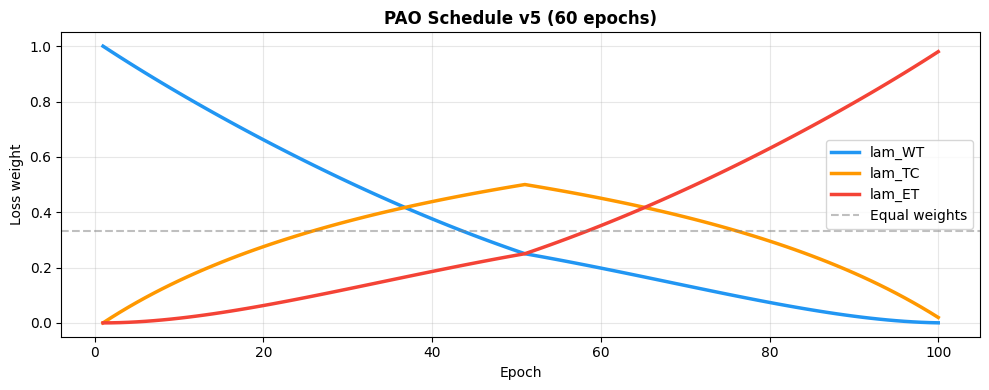

PAO Loss v5 with contrastive alignment and text gating supervision ready on cuda


In [7]:
# Cell 7 - PAO Loss v5 with CLIP Alignment and Supervised Text Gating Loss
# FIX: BoundaryLoss.get_boundary uses keyword args for .to()
# Model v5 returns 8 outputs: wt, tc, et, ds4_out, ds2_out, proj_vis, proj_txt, gates

def get_pao_weights(epoch, total_epochs):
    t = epoch - 1; T = total_epochs
    w_wt = max(math.cos(math.pi*t/(2*T))**2, 0)
    w_tc = max(1 - abs(2*t/T - 1), 0)
    w_et = max(math.sin(math.pi*t/(2*T))**2, 0)
    s = w_wt + w_tc + w_et + 1e-8
    return w_wt/s, w_tc/s, w_et/s

def get_et_tversky_alpha(epoch, total_epochs):
    return 0.50 + 0.35 * (epoch / total_epochs)

def visualize_pao_schedule(total_epochs=60):
    epochs = range(1, total_epochs+1)
    wts, tcs, ets = [], [], []
    for e in epochs:
        w, t, et = get_pao_weights(e, total_epochs)
        wts.append(w); tcs.append(t); ets.append(et)
    fig, ax = plt.subplots(figsize=(10,4))
    ax.plot(epochs, wts, label="lam_WT", lw=2.5, color="#2196F3")
    ax.plot(epochs, tcs, label="lam_TC", lw=2.5, color="#FF9800")
    ax.plot(epochs, ets, label="lam_ET", lw=2.5, color="#F44336")
    ax.axhline(1/3, color="gray", ls="--", alpha=0.5, label="Equal weights")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss weight")
    ax.set_title("PAO Schedule v5 (60 epochs)", fontweight="bold")
    ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
    plt.savefig("/kaggle/working/pao_schedule.png", dpi=150, bbox_inches="tight")
    plt.show()

visualize_pao_schedule(NUM_EPOCHS)


class SinCosDiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        w = (torch.sin(math.pi * probs) * torch.cos(math.pi * probs)).pow(2) + 1.0
        p = (probs * w).view(probs.size(0), -1)
        g = targets.view(targets.size(0), -1)
        return (1 - (2*(p*g).sum(1) + self.smooth) / (p.sum(1) + g.sum(1) + self.smooth)).mean()


class FocalDiceLoss(nn.Module):
    def __init__(self, gamma=0.75, smooth=1e-6):
        super().__init__()
        self.gamma = gamma; self.smooth = smooth
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        p = probs.view(probs.size(0), -1)
        g = targets.view(targets.size(0), -1)
        dice = (2*(p*g).sum(1) + self.smooth) / (p.sum(1) + g.sum(1) + self.smooth)
        return ((1 - dice)**self.gamma * (1 - dice)).mean()


class TverskyLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, targets, alpha=0.7):
        probs = torch.sigmoid(logits)
        p = probs.view(probs.size(0), -1)
        g = targets.view(targets.size(0), -1)
        tp = (p*g).sum(1); fp = (p*(1-g)).sum(1); fn = ((1-p)*g).sum(1)
        beta = 1.0 - alpha
        return (1 - (tp + self.smooth) / (tp + alpha*fn + beta*fp + self.smooth)).mean()


class BoundaryLoss(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32)
        ky = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=torch.float32)
        self.register_buffer("kx", kx.view(1,1,3,3))
        self.register_buffer("ky", ky.view(1,1,3,3))
    def get_boundary(self, mask):
        kx = self.kx.to(dtype=mask.dtype, device=mask.device)
        ky = self.ky.to(dtype=mask.dtype, device=mask.device)
        gx = F.conv2d(mask, kx, padding=1); gy = F.conv2d(mask, ky, padding=1)
        return (torch.sqrt(gx**2 + gy**2 + 1e-8) > 0.1).float()
    def forward(self, logits, targets):
        bnd = self.get_boundary(targets.float())
        return F.binary_cross_entropy_with_logits(
            logits.float(), targets.float(),
            weight=(1.0 + 5.0*bnd).float(), reduction="mean")


class CLIPAlignmentLoss(nn.Module):
    """InfoNCE loss to align projected vision bottleneck and text embeddings."""
    def __init__(self, temperature=0.07):
        super().__init__()
        self.temp = temperature
    def forward(self, img_embed, txt_embed):
        img_n = F.normalize(img_embed, dim=-1)
        txt_n = F.normalize(txt_embed, dim=-1)
        logits = (img_n @ txt_n.T) / self.temp
        B = logits.size(0)
        labels = torch.arange(B, device=logits.device)
        loss_i = F.cross_entropy(logits, labels)
        loss_t = F.cross_entropy(logits.T, labels)
        return (loss_i + loss_t) / 2


class PAOLoss(nn.Module):
    def __init__(self, align_coeff=0.10):
        super().__init__()
        self.focal_dice  = FocalDiceLoss(gamma=0.75)
        self.sincos_dice = SinCosDiceLoss()
        self.tversky     = TverskyLoss()
        self.boundary    = BoundaryLoss()
        self.clip_align  = CLIPAlignmentLoss()
        self.align_coeff = align_coeff

    def region_loss(self, logits, targets, use_tversky=True, use_boundary=True, tv_alpha=0.7):
        l_fd  = self.focal_dice(logits, targets)
        l_sc  = self.sincos_dice(logits, targets)
        l_bce = F.binary_cross_entropy_with_logits(logits, targets)
        if use_tversky and use_boundary:
            l_tv = self.tversky(logits, targets, alpha=tv_alpha)
            l_bd = self.boundary(logits, targets)
            return 0.30*l_fd + 0.25*l_sc + 0.20*l_tv + 0.15*l_bce + 0.10*l_bd
        elif use_tversky:
            l_tv = self.tversky(logits, targets, alpha=tv_alpha)
            return 0.35*l_fd + 0.30*l_sc + 0.25*l_tv + 0.10*l_bce
        else:
            return 0.45*l_fd + 0.35*l_sc + 0.20*l_bce

    def tc_selectivity_loss(self, tc_logits, wt_mask, tc_mask):
        pure_edema = (wt_mask - tc_mask).clamp(0, 1)
        return (torch.sigmoid(tc_logits) * pure_edema).mean()

    def et_recall_loss(self, et_logits, et_mask):
        pw = torch.tensor(8.0, device=et_logits.device)
        return F.binary_cross_entropy_with_logits(
            et_logits, et_mask, pos_weight=pw, reduction="mean")

    def forward(self, wt_l, tc_l, et_l, ds4_out, ds2_out,
                wt_m, tc_m, et_m, epoch, total_epochs,
                proj_vis=None, proj_txt=None, gates=None):
        lam_wt, lam_tc, lam_et = get_pao_weights(epoch, total_epochs)
        et_alpha = get_et_tversky_alpha(epoch, total_epochs)

        l_wt = self.region_loss(wt_l, wt_m, use_tversky=False, use_boundary=True)
        l_tc = self.region_loss(tc_l, tc_m, use_tversky=True,  use_boundary=True,  tv_alpha=0.65)
        l_et = self.region_loss(et_l, et_m, use_tversky=True,  use_boundary=True,  tv_alpha=et_alpha)

        l_tc_sel = self.tc_selectivity_loss(tc_l, wt_m, tc_m)
        l_et_rec = self.et_recall_loss(et_l, et_m)

        def ds_loss(ds_out, ta):
            return (
                self.region_loss(ds_out[:,0:1], wt_m, use_tversky=False, use_boundary=False) +
                self.region_loss(ds_out[:,1:2], tc_m, use_tversky=True,  use_boundary=False, tv_alpha=0.65) +
                self.region_loss(ds_out[:,2:3], et_m, use_tversky=True,  use_boundary=False, tv_alpha=ta)
            ) / 3

        l_ds = 0.60 * ds_loss(ds4_out, ta=0.65) + 0.40 * ds_loss(ds2_out, ta=et_alpha)

        wt_p = torch.sigmoid(wt_l); tc_p = torch.sigmoid(tc_l); et_p = torch.sigmoid(et_l)
        l_cons = (tc_p*(1-wt_p)).mean() + (et_p*(1-tc_p)).mean()

        total = (lam_wt * l_wt +
                 lam_tc * (l_tc + 0.15*l_tc_sel) +
                 lam_et * (l_et + 0.10*l_et_rec) +
                 0.08*l_ds + 0.04*l_cons)

        l_align = 0.0
        if proj_vis is not None and proj_txt is not None:
            l_align = self.clip_align(proj_vis, proj_txt)
            total = total + self.align_coeff * l_align

        # Supervised dynamic gating loss: Binary Cross Entropy against whether masks actually contain pixels
        l_gate = 0.0
        if gates is not None:
            y_wt = (wt_m.flatten(1).sum(1) > 5).float()
            y_tc = (tc_m.flatten(1).sum(1) > 5).float()
            y_et = (et_m.flatten(1).sum(1) > 5).float()
            targets_gate = torch.stack([y_wt, y_tc, y_et], dim=1) # (B, 3)
            if gates.device.type == "cuda":
                with torch.cuda.amp.autocast(enabled=False):
                    l_gate = F.binary_cross_entropy(gates.float(), targets_gate.float(), reduction="mean")
            else:
                l_gate = F.binary_cross_entropy(gates.float(), targets_gate.float(), reduction="mean")
            total = total + 0.05 * l_gate

        return total, {
            "wt":      l_wt.item(),
            "tc":      l_tc.item(),
            "et":      l_et.item(),
            "tc_sel":  l_tc_sel.item(),
            "et_rec":  l_et_rec.item(),
            "ds":      l_ds.item(),
            "align":   l_align.item() if isinstance(l_align, torch.Tensor) else l_align,
            "gate":    l_gate.item() if isinstance(l_gate, torch.Tensor) else l_gate,
            "lam_wt":  lam_wt,
            "lam_tc":  lam_tc,
            "lam_et":  lam_et,
            "et_alpha": et_alpha,
        }


criterion = PAOLoss(align_coeff=ALIGN_COEFF).to(DEVICE)
print("PAO Loss v5 with contrastive alignment and text gating supervision ready on", DEVICE)


In [8]:
# Cell 8 — Metrics
def dice_metric(logits, targets, threshold=0.5):
    probs = (torch.sigmoid(logits) > threshold).float()
    scores = []
    for i in range(logits.size(0)):
        p = probs[i].view(-1); g = targets[i].view(-1)
        if g.sum()==0 and p.sum()==0:
            continue
        tp  = (p*g).sum()
        den = p.sum()+g.sum()+1e-6
        scores.append((2*tp/den).item())
    return float(np.mean(scores)) if scores else 0.0

def hausdorff95_2d(pred_np, gt_np):
    pb = pred_np.astype(bool); gb = gt_np.astype(bool)
    if not pb.any() or not gb.any():
        return np.nan
    dt_gt   = distance_transform_edt(~gb)
    dt_pred = distance_transform_edt(~pb)
    return max(np.percentile(dt_gt[pb],95), np.percentile(dt_pred[gb],95))

print("Metrics ready")

Metrics ready


Starting fresh ...

  GNResUNet2D v5 Multimodal U-Net++ — Dynamic VLM Gating
  Regions: WT+TC+ET | Epochs: 1->100



Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

  Train:   0%|          | 0/1068 [00:00<?, ?it/s]

/tmp/ipykernel_58/702688905.py:184: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


    Val:   0%|          | 0/367 [00:00<?, ?it/s]

...

Ep 09/100 [261s] | driver=raw | RAW  WT 0.8125 TC 0.4222 ET 0.2383 Comp 0.4083 (best@thr 0.4995) | EMA  WT 0.6744 TC 0.0000 ET 0.0000 Comp 0.1349 (best@thr 0.2365) | lam=[0.85,0.14,0.01] a_ET=0.53 | LR enc=2.0e-05 dec=9.9e-05 |raw-window, not counted (driver=raw)


  Train:   0%|          | 0/1068 [00:00<?, ?it/s]

    Val:   0%|          | 0/367 [00:00<?, ?it/s]

    Val:   0%|          | 0/367 [00:00<?, ?it/s]

Ep 10/100 [261s] | driver=raw | RAW  WT 0.8160 TC 0.4365 ET 0.2644 Comp 0.4263 (best@thr 0.5099) | EMA  WT 0.6999 TC 0.0000 ET 0.0000 Comp 0.1400 (best@thr 0.2388) | lam=[0.83,0.15,0.02] a_ET=0.54 | LR enc=2.0e-05 dec=9.8e-05 | * best (src=raw)


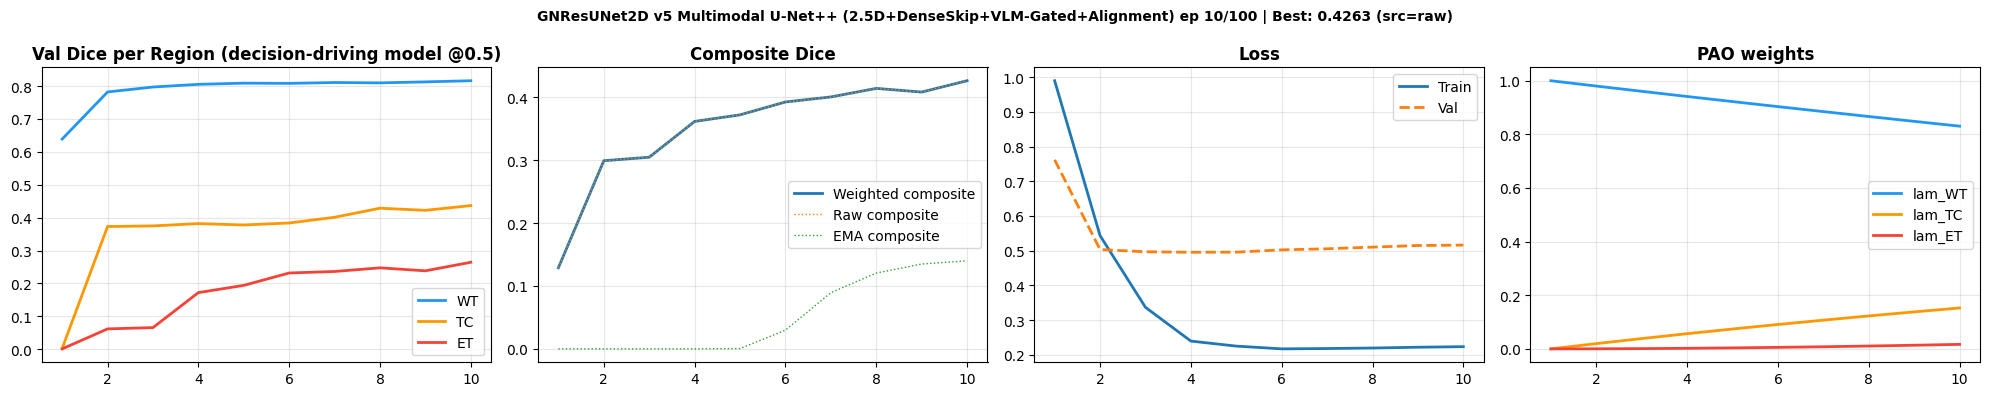

  Train:   0%|          | 0/1068 [00:00<?, ?it/s]

    Val:   0%|          | 0/367 [00:00<?, ?it/s]

    Val:   0%|          | 0/367 [00:00<?, ?it/s]

Ep 11/100 [261s] | driver=raw | RAW  WT 0.8184 TC 0.4425 ET 0.2642 Comp 0.4285 (best@thr 0.5124) | EMA  WT 0.7119 TC 0.0000 ET 0.0000 Comp 0.1424 (best@thr 0.2430) | lam=[0.81,0.17,0.02] a_ET=0.54 | LR enc=2.0e-05 dec=9.8e-05 | * best (src=raw)


  Train:   0%|          | 0/1068 [00:00<?, ?it/s]

...

  Train:   0%|          | 0/1068 [00:00<?, ?it/s]

    Val:   0%|          | 0/367 [00:00<?, ?it/s]

    Val:   0%|          | 0/367 [00:00<?, ?it/s]

Ep 15/100 [262s] | driver=raw | RAW  WT 0.8116 TC 0.4413 ET 0.2718 Comp 0.4306 (best@thr 0.5131) | EMA  WT 0.7328 TC 0.1412 ET 0.0000 Comp 0.1889 (best@thr 0.3417) | lam=[0.74,0.22,0.04] a_ET=0.55 | LR enc=1.9e-05 dec=9.6e-05 |raw-window, not counted (driver=raw)


  Train:   0%|          | 0/1068 [00:00<?, ?it/s]

In [ ]:
# Cell 9 - Training v5
# FIX: autocast('cuda') — device arg required in torch.amp
# FIX: GradScaler('cuda') — correct torch.amp usage
# FIX (6.1 audit, training-schedule): dual raw/EMA scoring with dynamic crossover,
#      single-cosine LR w/ warmup decoupled from patience, fixed-threshold weighted
#      checkpoint metric, and best-checkpoint source tracking. See cell comments below.

CKPT_PATH      = "/kaggle/working/gnresunet_pao_best.pth"
RESUME_PATH    = "/kaggle/working/gnresunet_pao_resume.pth"
HISTORY_PATH   = "/kaggle/working/gnresunet_pao_history.json"
EMA_PATH       = "/kaggle/working/gnresunet_pao_ema.pth"
BEST_META_PATH = "/kaggle/working/gnresunet_pao_best_meta.json"

for f in [CKPT_PATH, RESUME_PATH, HISTORY_PATH, EMA_PATH, BEST_META_PATH]:
    if os.path.exists(f): os.remove(f)

def load_history():
    if os.path.exists(HISTORY_PATH):
        with open(HISTORY_PATH) as f:
            return json.load(f)
    return {
        "train_loss":[], "val_loss":[],
        # decision-driving model's fixed-threshold (0.5) scores — same field names as before
        # for backward-compatible plotting, but semantics per the 6.1 audit fix.
        "val_dice_wt":[], "val_dice_tc":[],
        "val_dice_et":[], "val_dice_avg":[],
        "lam_wt":[], "lam_tc":[], "lam_et":[],
        # audit fields: raw vs EMA breakdown, every epoch, both scored models
        "val_composite_raw":[], "val_composite_ema":[],
        "val_dice_wt_raw":[], "val_dice_tc_raw":[], "val_dice_et_raw":[],
        "val_dice_wt_ema":[], "val_dice_tc_ema":[], "val_dice_et_ema":[],
        "val_avg_best_threshold_raw":[], "val_avg_best_threshold_ema":[],
        "driver":[],
        "best_model_source": None,
    }

def save_history(h):
    with open(HISTORY_PATH, "w") as f:
        json.dump(h, f, indent=2)


class ModelEMA:
    def __init__(self, model, decay=0.9998):
        import copy
        self.model = copy.deepcopy(model).eval()
        self.decay = decay
    @torch.no_grad()
    def update(self, model):
        for ep, p in zip(self.model.parameters(), model.parameters()):
            if p.requires_grad:
                ep.data.mul_(self.decay).add_(p.data, alpha=1-self.decay)
    def state_dict(self):
        return self.model.state_dict()


def get_param_groups(model, base_lr, encoder_mult=0.2):
    """Layer-wise Learning Rate: pre-trained encoder + text_encoder x0.2, new decoder x1.0."""
    encoder_names = {
        "enc0", "enc1", "enc2", "enc3", "enc4", "maxpool",
        "text_encoder"
    }
    enc_params, dec_params = [], []
    for name, param in model.named_parameters():
        root = name.split(".")[0]
        if root in encoder_names:
            if param.requires_grad:
                enc_params.append(param)
        else:
            if param.requires_grad:
                dec_params.append(param)
    return [
        {"params": enc_params, "lr": base_lr * encoder_mult, "name": "encoder"},
        {"params": dec_params, "lr": base_lr,                "name": "decoder"},
    ]


optimizer = torch.optim.AdamW(
    get_param_groups(model, LR, encoder_mult=0.2), weight_decay=1e-4)

# FIX (#3, #4): single cosine schedule (no restarts) over the full epoch budget,
# with a short linear warmup first. Restarts previously collided with early-stop
# patience (a restart at epoch 21 got killed 4 epochs later before it could help).
WARMUP_EPOCHS = 2
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=max(NUM_EPOCHS - WARMUP_EPOCHS, 1), eta_min=LR*0.01)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[WARMUP_EPOCHS])

scaler = GradScaler("cuda")
ema    = ModelEMA(model, decay=0.9998)   # decay unchanged — see audit note on why 0.9998 is correct
GRAD_ACCUM = 2

# FIX (#2): dynamic (data-driven) raw->EMA crossover instead of a fixed epoch cutoff.
MIN_CROSSOVER_EPOCH = 10     # safety rail: don't allow crossover before EMA has enough updates
# FIX (#6): patience no longer counts during the raw-driven window. If EMA never
# overtakes raw by this epoch, start counting on raw anyway so training can still stop.
PATIENCE_FALLBACK_EPOCH = 45
FIXED_THRESHOLD = 0.5
COMPOSITE_WEIGHTS = {"wt": 0.2, "tc": 0.3, "et": 0.5}   # FIX (#7): weighted, not unweighted avg

history       = load_history()
start_epoch   = len(history["train_loss"]) + 1
best_val_dice = max(history["val_dice_avg"]) if history["val_dice_avg"] else 0.0
no_improve    = 0
patience      = 35   # FIX (#6): raised from 20
crossover_happened = False
best_model_source  = history.get("best_model_source")

if os.path.exists(RESUME_PATH):
    ckpt = torch.load(RESUME_PATH, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scheduler.load_state_dict(ckpt["scheduler_state"])
    scaler.load_state_dict(ckpt["scaler_state"])
    ema.model.load_state_dict(ckpt["ema_state"])
    best_val_dice      = ckpt["best_val_dice"]
    no_improve         = ckpt["no_improve"]
    crossover_happened = ckpt.get("crossover_happened", False)
    best_model_source  = ckpt.get("best_model_source", best_model_source)
    print(f"Resumed at epoch {start_epoch}, best {best_val_dice:.4f}, "
          f"crossover_happened={crossover_happened}")
else:
    print("Starting fresh ...")


def train_epoch(loader, epoch):
    model.train()
    tl = n = 0
    comp_last = {"lam_wt":0,"lam_tc":0,"lam_et":0,"et_alpha":0}
    optimizer.zero_grad(set_to_none=True)
    bar = tqdm(loader, desc="  Train", leave=False, colour="green", dynamic_ncols=True)

    for step, (imgs, masks, pids, input_ids, attention_mask) in enumerate(bar):
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)

        with autocast("cuda"):
            wt, tc, et, ds4, ds2, proj_vis, proj_txt, gates = model(imgs, input_ids, attention_mask)
            loss, comps = criterion(
                wt, tc, et, ds4, ds2,
                masks[:,0:1], masks[:,1:2], masks[:,2:3],
                epoch, NUM_EPOCHS,
                proj_vis, proj_txt, gates)
            loss = loss / GRAD_ACCUM

        # NaN guard
        if not torch.isfinite(loss):
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.scale(loss).backward()

        if (step+1) % GRAD_ACCUM == 0 or (step+1) == len(loader):
            scaler.unscale_(optimizer)
            has_nan = any(
                p.grad is not None and not torch.isfinite(p.grad).all()
                for p in model.parameters())
            if has_nan:
                optimizer.zero_grad(set_to_none=True)
                scaler.update()
                continue
            torch.nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            ema.update(model)

        bs = imgs.size(0)
        tl += loss.item() * GRAD_ACCUM * bs
        n  += bs
        comp_last = comps
        bar.set_postfix(
            loss=f"{loss.item()*GRAD_ACCUM:.4f}",
            lam_et=f"{comps['lam_et']:.2f}",
            a_et=f"{comps['et_alpha']:.2f}")

    return tl / n, comp_last


def dice_with_threshold(logits, targets, threshold):
    probs = (torch.sigmoid(logits) > threshold).float()
    scores = []
    for i in range(logits.size(0)):
        p = probs[i].view(-1); g = targets[i].view(-1)
        if g.sum() == 0 and p.sum() == 0:
            continue
        scores.append((2*(p*g).sum() / (p.sum()+g.sum()+1e-6)).item())
    return scores


def val_epoch(loader, epoch, eval_model):
    """
    FIX (#7): checkpoint/early-stop decisions must use a single fixed threshold
    (0.5) so per-epoch threshold sweeping can't inflate the metric. The sweep is
    kept as a diagnostic-only value (best-threshold avg), logged but not acted on.
    Returns: loss, d_wt@0.5, d_tc@0.5, d_et@0.5, weighted_composite@0.5, best_threshold_avg
    """
    eval_model.eval()
    tl = n = 0
    thresholds = list(np.arange(0.30, 0.66, 0.05))
    all_wt = {t: [] for t in thresholds}
    all_tc = {t: [] for t in thresholds}
    all_et = {t: [] for t in thresholds}
    fixed_wt, fixed_tc, fixed_et = [], [], []

    with torch.no_grad():
        for imgs, masks, pids, input_ids, attention_mask in tqdm(loader, desc="    Val", leave=False,
                                    colour="blue", dynamic_ncols=True):
            imgs  = imgs.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)
            input_ids = input_ids.to(DEVICE, non_blocking=True)
            attention_mask = attention_mask.to(DEVICE, non_blocking=True)
            with autocast("cuda"):
                wt, tc, et, ds4, ds2, proj_vis, proj_txt, gates = eval_model(imgs, input_ids, attention_mask)
                loss, _ = criterion(
                    wt, tc, et, ds4, ds2,
                    masks[:,0:1], masks[:,1:2], masks[:,2:3],
                    epoch, NUM_EPOCHS,
                    proj_vis, proj_txt, gates)
            tl += loss.item() * imgs.size(0); n += imgs.size(0)
            for t in thresholds:
                all_wt[t] += dice_with_threshold(wt, masks[:,0:1], t)
                all_tc[t] += dice_with_threshold(tc, masks[:,1:2], t)
                all_et[t] += dice_with_threshold(et, masks[:,2:3], t)
            fixed_wt += dice_with_threshold(wt, masks[:,0:1], FIXED_THRESHOLD)
            fixed_tc += dice_with_threshold(tc, masks[:,1:2], FIXED_THRESHOLD)
            fixed_et += dice_with_threshold(et, masks[:,2:3], FIXED_THRESHOLD)

    def best_score(d):
        valid = {t: v for t, v in d.items() if v}
        if not valid:
            return 0.0
        best_t = max(valid, key=lambda t: float(np.mean(valid[t])))
        return float(np.mean(valid[best_t]))

    d_wt = float(np.mean(fixed_wt)) if fixed_wt else 0.0
    d_tc = float(np.mean(fixed_tc)) if fixed_tc else 0.0
    d_et = float(np.mean(fixed_et)) if fixed_et else 0.0
    composite = (COMPOSITE_WEIGHTS["wt"]*d_wt + COMPOSITE_WEIGHTS["tc"]*d_tc
                 + COMPOSITE_WEIGHTS["et"]*d_et)
    best_threshold_avg = (best_score(all_wt) + best_score(all_tc) + best_score(all_et)) / 3

    return tl/n, d_wt, d_tc, d_et, composite, best_threshold_avg


def plot_progress(h):
    if len(h["train_loss"]) < 2:
        return
    eps = range(1, len(h["train_loss"])+1)
    fig, axes = plt.subplots(1, 4, figsize=(20,4))
    for name, vals, col in [("WT",h["val_dice_wt"],"#2196F3"),
                              ("TC",h["val_dice_tc"],"#FF9800"),
                              ("ET",h["val_dice_et"],"#F44336")]:
        axes[0].plot(eps, vals, label=name, lw=2, color=col)
    axes[0].set_title("Val Dice per Region (decision-driving model @0.5)", fontweight="bold")
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(eps, h["val_dice_avg"], lw=2, label="Weighted composite")
    axes[1].plot(eps, h["val_composite_raw"], lw=1, ls=":", label="Raw composite")
    axes[1].plot(eps, h["val_composite_ema"], lw=1, ls=":", label="EMA composite")
    axes[1].set_title("Composite Dice", fontweight="bold")
    axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[2].plot(eps, h["train_loss"], label="Train", lw=2)
    axes[2].plot(eps, h["val_loss"],   label="Val",   lw=2, ls="--")
    axes[2].set_title("Loss", fontweight="bold")
    axes[2].legend(); axes[2].grid(alpha=0.3)
    for name, vals, col in [("lam_WT",h["lam_wt"],"#2196F3"),
                              ("lam_TC",h["lam_tc"],"#FF9800"),
                              ("lam_ET",h["lam_et"],"#F44336")]:
        axes[3].plot(eps, vals, label=name, lw=2, color=col)
    axes[3].set_title("PAO weights", fontweight="bold")
    axes[3].legend(); axes[3].grid(alpha=0.3)
    plt.suptitle(
        f"GNResUNet2D v5 Multimodal U-Net++ (2.5D+DenseSkip+VLM-Gated+Alignment) "
        f"ep {len(h['train_loss'])}/{NUM_EPOCHS} | Best: {best_val_dice:.4f} "
        f"(src={h.get('best_model_source')})",
        fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.savefig("/kaggle/working/training_curves.png", dpi=130, bbox_inches="tight")
    plt.show()


print(f"\n{'='*65}")
print("  GNResUNet2D v5 Multimodal U-Net++ — Dynamic VLM Gating")
print(f"  Regions: WT+TC+ET | Epochs: {start_epoch}->{NUM_EPOCHS}")
print(f"{'='*65}\n")

epoch_bar = trange(start_epoch, NUM_EPOCHS+1, desc="Epochs",
                   colour="cyan", dynamic_ncols=True)

for epoch in epoch_bar:
    t0 = time.time()
    tr_loss, comps = train_epoch(train_loader, epoch)

    # FIX (#1): score every epoch with BOTH raw and EMA models.
    va_loss_raw, wt_r, tc_r, et_r, comp_raw, bta_raw = val_epoch(val_loader, epoch, model)
    va_loss_ema, wt_e, tc_e, et_e, comp_ema, bta_ema = val_epoch(val_loader, epoch, ema.model)

    # FIX (#2): dynamic crossover — one-way switch from raw to EMA authority.
    if (not crossover_happened) and epoch >= MIN_CROSSOVER_EPOCH and comp_ema > comp_raw:
        crossover_happened = True
        print(f"  >>> EMA crossover triggered at epoch {epoch} "
              f"(EMA {comp_ema:.4f} > raw {comp_raw:.4f}) — decisions now EMA-driven")

    driver = "ema" if crossover_happened else "raw"
    if driver == "ema":
        va_loss, va_wt, va_tc, va_et, va_avg = va_loss_ema, wt_e, tc_e, et_e, comp_ema
    else:
        va_loss, va_wt, va_tc, va_et, va_avg = va_loss_raw, wt_r, tc_r, et_r, comp_raw

    scheduler.step()
    elapsed = time.time() - t0

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["val_dice_wt"].append(va_wt);  history["val_dice_tc"].append(va_tc)
    history["val_dice_et"].append(va_et);  history["val_dice_avg"].append(va_avg)
    history["lam_wt"].append(comps["lam_wt"])
    history["lam_tc"].append(comps["lam_tc"])
    history["lam_et"].append(comps["lam_et"])
    history["val_composite_raw"].append(comp_raw); history["val_composite_ema"].append(comp_ema)
    history["val_dice_wt_raw"].append(wt_r); history["val_dice_tc_raw"].append(tc_r); history["val_dice_et_raw"].append(et_r)
    history["val_dice_wt_ema"].append(wt_e); history["val_dice_tc_ema"].append(tc_e); history["val_dice_et_ema"].append(et_e)
    history["val_avg_best_threshold_raw"].append(bta_raw)
    history["val_avg_best_threshold_ema"].append(bta_ema)
    history["driver"].append(driver)

    # FIX (#6): patience only counts once we're on a stable EMA-driven "best" definition,
    # or once we've waited long enough that we shouldn't keep waiting for a crossover.
    patience_active = crossover_happened or (epoch >= PATIENCE_FALLBACK_EPOCH)

    if va_avg > best_val_dice:
        best_val_dice = va_avg; no_improve = 0
        best_model_source = driver
        history["best_model_source"] = best_model_source
        # FIX (#8): always save both, but record which one is actually "best".
        torch.save(model.state_dict(), CKPT_PATH)
        torch.save(ema.state_dict(),   EMA_PATH)
        with open(BEST_META_PATH, "w") as f:
            json.dump({"source": best_model_source, "epoch": epoch,
                       "best_val_dice": best_val_dice}, f, indent=2)
        tag = f" * best (src={best_model_source})"
    else:
        if patience_active:
            no_improve += 1
            tag = f"no imp {no_improve}/{patience} (driver={driver})"
        else:
            tag = f"raw-window, not counted (driver={driver})"

    save_history(history)

    torch.save({
        "epoch": epoch,
        "model_state":        model.state_dict(),
        "optimizer_state":    optimizer.state_dict(),
        "scheduler_state":    scheduler.state_dict(),
        "scaler_state":       scaler.state_dict(),
        "ema_state":          ema.state_dict(),
        "best_val_dice":      best_val_dice,
        "no_improve":         no_improve,
        "crossover_happened": crossover_happened,
        "best_model_source":  best_model_source,
    }, RESUME_PATH)

    lr_enc = optimizer.param_groups[0]["lr"]
    lr_dec = optimizer.param_groups[1]["lr"]
    print(
        f"Ep {epoch:02d}/{NUM_EPOCHS} [{elapsed:.0f}s] | driver={driver} | "
        f"RAW  WT {wt_r:.4f} TC {tc_r:.4f} ET {et_r:.4f} Comp {comp_raw:.4f} (best@thr {bta_raw:.4f}) | "
        f"EMA  WT {wt_e:.4f} TC {tc_e:.4f} ET {et_e:.4f} Comp {comp_ema:.4f} (best@thr {bta_ema:.4f}) | "
        f"lam=[{comps['lam_wt']:.2f},{comps['lam_tc']:.2f},{comps['lam_et']:.2f}] "
        f"a_ET={comps['et_alpha']:.2f} | "
        f"LR enc={lr_enc:.1e} dec={lr_dec:.1e} |{tag}")

    if epoch % 10 == 0 or epoch == NUM_EPOCHS:
        plot_progress(history)
    if patience_active and no_improve >= patience:
        print(f"\nEarly stop at epoch {epoch} (driver={driver})")
        break

print(f"\nBest avg Dice: {best_val_dice:.4f} (source={best_model_source})")
plot_progress(history)

In [11]:
# Cell 10 - Final evaluation v5 (EMA + TTA, 2.5D Multimodal)
# FIX: autocast('cuda') throughout
# FIX (#8, 6.1 audit): load whichever checkpoint (raw or EMA) actually produced the
# best score, instead of unconditionally loading EMA.

def tta_predict(eval_model, imgs, input_ids=None, attention_mask=None):
    """
    8-variant TTA (adapted for 2D/2.5D multimodal with 8 outputs).
    """
    all_wt, all_tc, all_et = [], [], []
    flip_configs = [
        [],       # original
        [3],      # h-flip
        [2],      # v-flip
        [2,3],    # h+v flip
    ]
    with autocast("cuda"):
        for fdims in flip_configs:
            x = torch.flip(imgs, dims=fdims) if fdims else imgs
            wt, tc, et, _, _, _, _, _ = eval_model(x, input_ids, attention_mask)
            if fdims:
                wt=torch.flip(wt,dims=fdims); tc=torch.flip(tc,dims=fdims); et=torch.flip(et,dims=fdims)
            all_wt.append(torch.sigmoid(wt))
            all_tc.append(torch.sigmoid(tc))
            all_et.append(torch.sigmoid(et))
            
        for fdims in flip_configs:
            x = torch.flip(imgs, dims=fdims) if fdims else imgs
            x_t = x.transpose(2, 3)
            wt, tc, et, _, _, _, _, _ = eval_model(x_t, input_ids, attention_mask)
            wt=wt.transpose(2,3); tc=tc.transpose(2,3); et=et.transpose(2,3)
            if fdims:
                wt=torch.flip(wt,dims=fdims); tc=torch.flip(tc,dims=fdims); et=torch.flip(et,dims=fdims)
            all_wt.append(torch.sigmoid(wt))
            all_tc.append(torch.sigmoid(tc))
            all_et.append(torch.sigmoid(et))
            
    p_wt = torch.stack(all_wt).mean(0)
    p_tc = torch.stack(all_tc).mean(0)
    p_et = torch.stack(all_et).mean(0)
    return p_wt, p_tc, p_et


# FIX (#8): determine which side of the raw/EMA crossover actually produced the
# best checkpoint, and load that one — not an unconditional EMA load.
best_source = "ema"  # default/fallback if no metadata is found
if os.path.exists(BEST_META_PATH):
    with open(BEST_META_PATH) as f:
        best_meta = json.load(f)
    best_source = best_meta.get("source", "ema")
    print(f"Best checkpoint metadata: source={best_source}, "
          f"epoch={best_meta.get('epoch')}, best_val_dice={best_meta.get('best_val_dice')}")
else:
    print("No best-checkpoint metadata found — defaulting to EMA checkpoint")

if best_source == "raw":
    raw_state = torch.load(CKPT_PATH, map_location=DEVICE)
    ema.model.load_state_dict(raw_state)
    print("Best RAW model loaded (raw model outperformed EMA at checkpoint time)")
else:
    ema_state = torch.load(EMA_PATH, map_location=DEVICE)
    ema.model.load_state_dict(ema_state)
    print("Best EMA model loaded")
ema.model.eval()

patient_probs = defaultdict(lambda: {"wt":[], "tc":[], "et":[]})
patient_gts   = defaultdict(lambda: {"wt":[], "tc":[], "et":[]})

with torch.no_grad():
    for imgs, masks, pids, input_ids, attention_mask in tqdm(val_loader, desc="TTA Inference"):
        imgs = imgs.to(DEVICE)
        input_ids = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)
        
        p_wt, p_tc, p_et = tta_predict(ema.model, imgs, input_ids, attention_mask)
        m_np = masks.numpy()
        for i, pid in enumerate(pids.tolist()):
            patient_probs[pid]["wt"].append(p_wt[i,0].cpu().numpy())
            patient_probs[pid]["tc"].append(p_tc[i,0].cpu().numpy())
            patient_probs[pid]["et"].append(p_et[i,0].cpu().numpy())
            patient_gts[pid]["wt"].append(m_np[i,0])
            patient_gts[pid]["tc"].append(m_np[i,1])
            patient_gts[pid]["et"].append(m_np[i,2])

results = []
for pid in tqdm(patient_probs.keys(), desc="Aggregating"):
    pat = {}
    for region in ["wt","tc","et"]:
        pv = np.stack(patient_probs[pid][region])
        gv = np.stack(patient_gts[pid][region])
        if gv.sum() == 0:
            pat[region] = {"dice": np.nan, "hd95": np.nan}
            continue
        best_d = 0; best_p = None
        for t in np.arange(0.25, 0.71, 0.05):
            pb = (pv > t).astype(np.float32)
            tp = ((pb==1)&(gv==1)).sum()
            d  = 2*tp / (pb.sum()+gv.sum()+1e-6)
            if d > best_d:
                best_d = d; best_p = pb
        if best_p is None:
            best_p = (pv > 0.5).astype(np.float32)
        if best_p.any() and gv.astype(bool).any():
            dt_gt   = distance_transform_edt(~gv.astype(bool))
            dt_pred = distance_transform_edt(~best_p.astype(bool))
            hd = max(np.percentile(dt_gt[best_p.astype(bool)], 95),
                     np.percentile(dt_pred[gv.astype(bool)], 95))
        else:
            hd = np.nan
        pat[region] = {"dice": float(best_d),
                       "hd95": float(hd) if not np.isnan(hd) else None}
    avg_dice = np.nanmean([v["dice"] for v in pat.values()])
    hd_vals  = [v["hd95"] for v in pat.values() if v["hd95"] is not None]
    results.append({
        "pid":      pid,
        "dice_wt":  pat["wt"]["dice"], "dice_tc": pat["tc"]["dice"],
        "dice_et":  pat["et"]["dice"], "dice_avg": float(avg_dice),
        "hd95_wt":  pat["wt"]["hd95"], "hd95_tc": pat["tc"]["hd95"],
        "hd95_et":  pat["et"]["hd95"],
        "hd95_avg": float(np.mean(hd_vals)) if hd_vals else None,
    })


def safe_stats(lst):
    vals = [v for v in lst if v is not None and not np.isnan(v)]
    if not vals: return 0.0, 0.0
    return float(np.mean(vals)), float(np.median(vals))

d_wt  = [r["dice_wt"]  for r in results]; d_tc  = [r["dice_tc"]  for r in results]
d_et  = [r["dice_et"]  for r in results]; d_avg = [r["dice_avg"] for r in results]
h_wt  = [r["hd95_wt"]  for r in results]; h_tc  = [r["hd95_tc"]  for r in results]
h_et  = [r["hd95_et"]  for r in results]; h_avg = [r["hd95_avg"] for r in results]

print("\n" + "="*62)
print("GNResUNet2D v5 Multimodal - FINAL RESULTS")
print("2.5D FLAIR | BraTS2020 | WT+TC+ET | PubMedBERT + nested CBAM + VLM gating")
print(f"Best checkpoint source: {best_source}")
print("="*62)
print(f"{'Region':<8} {'Mean Dice':>10} {'Median':>10} {'Mean HD95':>10}")
print("-"*62)
for name, dices, hds in [("WT",d_wt,h_wt),("TC",d_tc,h_tc),
                          ("ET",d_et,h_et),("AVG",d_avg,h_avg)]:
    dm, dmed = safe_stats(dices)
    hm, _    = safe_stats(hds)
    print(f"{name:<8} {dm:>10.4f} {dmed:>10.4f} {hm:>10.4f}")
print("="*62)
print(f"Patients evaluated: {len(results)}")

with open("/kaggle/working/final_results_v3.json","w") as f:
    json.dump(results, f, indent=2)
print("Saved: final_results_v3.json")

Best checkpoint metadata: source=raw, epoch=36, best_val_dice=0.44334241237396166
Best RAW model loaded (raw model outperformed EMA at checkpoint time)


TTA Inference:   0%|          | 0/367 [00:00<?, ?it/s]

Aggregating:   0%|          | 0/86 [00:00<?, ?it/s]


GNResUNet2D v5 Multimodal - FINAL RESULTS
2.5D FLAIR | BraTS2020 | WT+TC+ET | PubMedBERT + nested CBAM + VLM gating
Best checkpoint source: raw
Region    Mean Dice     Median  Mean HD95
--------------------------------------------------------------
WT           0.9126     0.9258     2.0282
TC           0.7239     0.7760     8.1881
ET           0.5106     0.5675    11.1721
AVG          0.7230     0.7448     7.0653
Patients evaluated: 86
Saved: final_results_v3.json
